# Are prediction market prices good probabilities? Calibration and the favourite-longshot bias

**Objective:** part of my Graduating Project. If a Polymarket or Kalshi contract is used as the hedge of a structured note, its price is treated as a probability. Here we check if that is true with thousands of contracts that already resolved:

- **Calibration:** of the contracts that traded at 20 cents, did 20% of them pay?
- **Brier and log scores** by time to resolution
- **Favourite-longshot bias:** the return of buying contracts at each price (Snowberg and Wolfers, 2010; Page and Clemen, 2013). If cheap contracts (longshots) lose more than expensive ones, buying tail protection with event contracts is expensive.

**Data:**
- Polymarket: all the on-chain fills of January to September 2024 (Envio "Polymarket On-Chain v1" dataset on Hugging Face, CC-BY), aggregated to a daily price per outcome token, plus the resolution of each market from the ConditionalTokens contract. Polymarket's own website and API are blocked from Colombia, the on-chain data is public.
- Kalshi: hourly bid/ask of the "Bitcoin above K at 5 pm" contracts (KXBTCD), February 2025 to October 2026, from the public API.

Libraries of the project: `duckdb`, `pandas`, `numpy`, `matplotlib`, `seaborn` and `statsmodels`.

## Part 1. Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
import statsmodels.formula.api as smf

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
con = duckdb.connect()

## Part 2. Polymarket: resolved binary markets

The resolution comes from the ConditionalTokens contract: each condition has the list of its outcome tokens (`positionIds`) and the payout of each one (`payoutNumerators / payoutDenominator`). We keep binary markets (Yes/No) that ended between February and September 2024, and the first outcome token of each market (usually "Yes"). The join is done in `collect_polymarket.py`.

In [2]:
# collect_polymarket.py joins market_data and condition (500 MB together) and keeps this small table
tokens = con.sql("select * from 'data/polymarket/resolved_2024.parquet'").df()
tokens = tokens[tokens["payout"].isin([0.0, 1.0])]          # we leave out the rare markets resolved 50/50
print("Resolved binary markets that ended Feb-Sep 2024:", len(tokens))
print("Share that resolved Yes (first outcome):", round(tokens["payout"].mean(), 3))
tokens.sample(5, random_state=1)[["market", "end_date", "payout"]]

Resolved binary markets that ended Feb-Sep 2024: 6607
Share that resolved Yes (first outcome): 0.275


,market,end_date,payout
4270,Did Trump launch $RTR?,2024-08-12 12:00:00,0.0
6272,Will the fight reach the 8th round?,2024-09-21 12:00:00,0.0
972,Will Dallas Mavericks be 2023-24 NBA Champions?,2024-06-06 00:00:00,0.0
2429,Roaring Kitty billionaire before July?,2024-06-30 12:00:00,0.0
3483,Biden not drop out by July 26?,2024-07-26 12:00:00,0.0


In [3]:
precios = con.sql("select * from 'data/polymarket/daily_2024_*.parquet'").df()
precios["day"] = pd.to_datetime(precios["day"])
p = precios.merge(tokens, on="token")
p["days_before"] = (p["end_date"].dt.normalize() - p["day"]).dt.days
vol = p.groupby("token")["volume_usdc"].sum()
liquidos = vol[vol >= 1000].index                          # at least 1.000 USDC traded
p = p[p["token"].isin(liquidos) & (p["days_before"] >= 0)]
print("Markets with at least 1.000 USDC of volume:", p["token"].nunique(), "| daily prices:", len(p))

Markets with at least 1.000 USDC of volume: 3920 | daily prices: 50213


## Part 3. Price at 1, 7 and 30 days before the end

For each market and horizon h we take the volume-weighted price of the last day with trades that is at least h days before the end, and at most 5 days older than that (stale prices are dropped).

In [4]:
filas = []
for h in [1, 7, 30]:
    x = p[(p["days_before"] >= h) & (p["days_before"] <= h + 5)].sort_values("days_before").groupby("token").first().reset_index()
    x["horizon_days"] = h
    filas.append(x[["token", "market", "horizon_days", "vwap", "payout", "volume_usdc"]])
pm = pd.concat(filas)
pm = pm[(pm["vwap"] > 0) & (pm["vwap"] < 1)]
pm.groupby("horizon_days").size()

horizon_days
1     3186
7     1497
30     594
dtype: int64

## Part 4. Calibration

We group the prices in bins of 10 cents and compare the average price with the share of contracts that paid.

In [5]:
def calibracion(df, precio, resultado, bins=np.linspace(0, 1, 11)):
    d = df.copy()
    d["bin"] = pd.cut(d[precio], bins, include_lowest=True)
    return d.groupby("bin", observed=True).agg(n=(resultado, "size"), avg_price=(precio, "mean"), freq_paid=(resultado, "mean"))

def scores(df, precio, resultado):
    q = df[precio].clip(0.001, 0.999)
    y = df[resultado]
    return pd.Series({"n": len(df), "brier": ((q - y) ** 2).mean(), "log_score": -(y * np.log(q) + (1 - y) * np.log(1 - q)).mean(),
                      "brier_naive": ((y.mean() - y) ** 2).mean()})

print(pm.groupby("horizon_days").apply(lambda g: scores(g, "vwap", "payout")).round(4))
cal_pm = calibracion(pm[pm["horizon_days"] == 7], "vwap", "payout")
cal_pm.round(3)

                   n   brier  log_score  brier_naive
horizon_days                                        
1             3186.0  0.1355     0.4090       0.2386
7             1497.0  0.1172     0.3721       0.2123
30             594.0  0.1050     0.3327       0.1929


,n,avg_price,freq_paid
bin,,,
"(-0.001, 0.1]",569,0.034,0.042
"(0.1, 0.2]",216,0.147,0.153
"(0.2, 0.3]",154,0.247,0.240
"(0.3, 0.4]",115,0.347,0.348
"(0.4, 0.5]",72,0.449,0.458
"(0.5, 0.6]",73,0.553,0.466
"(0.6, 0.7]",63,0.653,0.794
"(0.7, 0.8]",39,0.749,0.718
"(0.8, 0.9]",54,0.851,0.778


The Brier score looks worse closer to the end, which is strange. The reason is the composition: many short-lived markets (for example daily crypto or sports questions) only exist in the last days, so the three horizons do not have the same markets. With the **same markets** at the three horizons the comparison is fair:

In [6]:
comunes = pm.groupby("token")["horizon_days"].nunique()
mismos = pm[pm["token"].isin(comunes[comunes == 3].index)]
print("Markets with a price at 1, 7 and 30 days:", mismos["token"].nunique())
mismos.groupby("horizon_days").apply(lambda g: scores(g, "vwap", "payout")).round(4)

Markets with a price at 1, 7 and 30 days: 409


,n,brier,log_score,brier_naive
horizon_days,,,,
1,409.0,0.0518,0.1719,0.1796
7,409.0,0.0709,0.2443,0.1796
30,409.0,0.1104,0.3479,0.1796


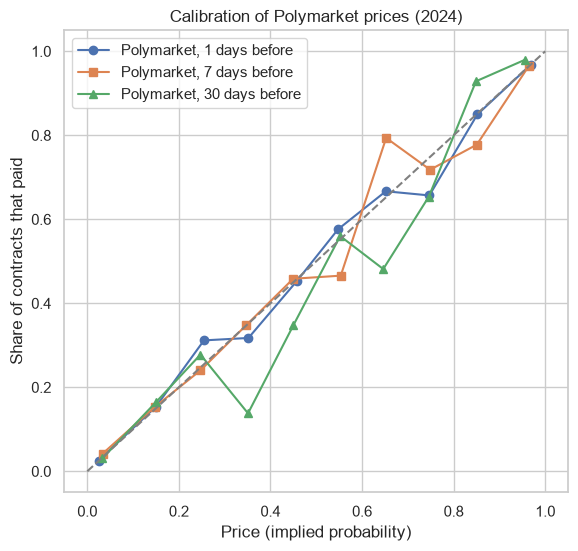

In [7]:
plt.figure(figsize=(6.5, 6))
for h, m in [(1, "o"), (7, "s"), (30, "^")]:
    c = calibracion(pm[pm["horizon_days"] == h], "vwap", "payout")
    plt.plot(c["avg_price"], c["freq_paid"], marker=m, label=f"Polymarket, {h} days before")
plt.plot([0, 1], [0, 1], ls="--", color="grey")
plt.title("Calibration of Polymarket prices (2024)")
plt.xlabel("Price (implied probability)")
plt.ylabel("Share of contracts that paid")
plt.legend()
plt.savefig("figures/calibration_polymarket.png", bbox_inches="tight")
plt.show()

## Part 5. The favourite-longshot bias

If we buy one contract at price p, the return is payout / p - 1. Under efficient pricing (and no risk premium) the expected return is 0 in every bin. A negative return for cheap contracts is the favourite-longshot bias.

In [8]:
def retornos(df, precio, resultado):
    d = df.copy()
    d["ret"] = d[resultado] / d[precio] - 1
    d["bin"] = pd.cut(d[precio], [0, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 1], include_lowest=True)
    return d.groupby("bin", observed=True).agg(n=("ret", "size"), avg_price=(precio, "mean"), freq_paid=(resultado, "mean"),
                                                return_per_dollar=("ret", "mean"))

flb_pm = retornos(pm[pm["horizon_days"] == 7], "vwap", "payout")
flb_pm.round(3)

,n,avg_price,freq_paid,return_per_dollar
bin,,,,
"(-0.001, 0.05]",411,0.019,0.027,0.969
"(0.05, 0.1]",158,0.072,0.082,0.209
"(0.1, 0.25]",300,0.169,0.180,0.055
"(0.25, 0.5]",257,0.356,0.346,-0.031
"(0.5, 0.75]",159,0.618,0.642,0.023
"(0.75, 0.9]",70,0.834,0.743,-0.111
"(0.9, 0.95]",43,0.925,0.907,-0.019
"(0.95, 1.0]",99,0.981,0.990,0.009


The return of the cheapest bin depends on a few contracts that paid 20 or 50 times the price, so it is very noisy. A bootstrap interval of the return of buying everything below 10 cents:

In [9]:
largo = pm[(pm["horizon_days"] == 7) & (pm["vwap"] <= 0.10)]
r = (largo["payout"] / largo["vwap"] - 1).values
np.random.seed(0)
boot = [np.mean(np.random.choice(r, len(r))) for _ in range(5000)]
print("Contracts below 10 cents:", len(r), "| mean return:", round(r.mean(), 3), "| 95% interval:", np.round(np.percentile(boot, [2.5, 97.5]), 3))
print("Median return:", np.median(r), "| share that paid:", round(largo["payout"].mean(), 3))

Contracts below 10 cents: 569 | mean return: 0.758 | 95% interval: [-0.336  2.591]
Median return: -1.0 | share that paid: 0.042


A formal test: regression of the outcome on the price (Page and Clemen, 2013). With perfect calibration the intercept is 0 and the slope is 1; a slope above 1 means cheap contracts are too expensive and expensive contracts too cheap.

In [10]:
m = smf.ols("payout ~ vwap", pm[pm["horizon_days"] == 7]).fit(cov_type="HC1")
print(m.summary().tables[1])
print("Test slope = 1:", m.t_test("vwap = 1"))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0081      0.010      0.844      0.399      -0.011       0.027
vwap           0.9803      0.023     42.473      0.000       0.935       1.026
Test slope = 1:                              Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.9803      0.023     -0.853      0.394       0.935       1.026


## Part 6. Kalshi: Bitcoin "above K" contracts

The same tests on Kalshi. Each contract pays 1 dollar if Bitcoin is above the strike at 5 pm New York. We use the mid between bid and ask 1, 6 and 24 hours before the close, and only quotes with a spread of 10 cents or less.

In [11]:
k = pd.read_parquet("data/kalshi_btc/candles_hourly.parquet")
mk = pd.read_csv("data/kalshi_btc/markets.csv")
k = k.merge(mk[["ticker", "strike", "result", "close_time"]], on="ticker")
k["close_ts"] = pd.to_datetime(k["close_time"]).astype("int64") // 10 ** 9
k["hours_before"] = ((k["close_ts"] - k["ts"]) / 3600).round()
k["mid"] = (k["bid"] + k["ask"]) / 2
k["paid"] = (k["result"] == "yes").astype(float)
k = k[(k["ask"] - k["bid"] <= 0.10) & (k["mid"] > 0) & (k["mid"] < 1)]
kal = k[k["hours_before"].isin([1, 6, 24])].copy()
print("Kalshi contracts:", kal["ticker"].nunique(), "| events (days):", kal["ticker"].str.rsplit("-", n=1).str[0].nunique())
print(kal.groupby("hours_before").apply(lambda g: scores(g, "mid", "paid")).round(4))

Kalshi contracts: 20570 | events (days): 838
                    n   brier  log_score  brier_naive
hours_before                                         
1.0           15789.0  0.0185     0.0720       0.2499
6.0           17981.0  0.0520     0.1797       0.2499
24.0          14701.0  0.0936     0.3020       0.2499


In [12]:
flb_k = retornos(kal[kal["hours_before"] == 24], "mid", "paid")
flb_k.round(3)

,n,avg_price,freq_paid,return_per_dollar
bin,,,,
"(-0.001, 0.05]",3282,0.024,0.016,-0.149
"(0.05, 0.1]",1102,0.074,0.068,-0.110
"(0.1, 0.25]",1585,0.168,0.165,-0.021
"(0.25, 0.5]",1643,0.372,0.390,0.049
"(0.5, 0.75]",1625,0.632,0.631,-0.001
"(0.75, 0.9]",1483,0.836,0.838,0.003
"(0.9, 0.95]",1116,0.931,0.949,0.019
"(0.95, 1.0]",2865,0.975,0.987,0.013


All the strikes of one day depend on the same Bitcoin close, so the contracts are not independent. The bootstrap resamples **days**, and the regression has errors clustered by day. We use the mid price; a buyer pays the ask, so the real return is lower.

In [13]:
x = kal[(kal["hours_before"] == 24) & (kal["mid"] <= 0.10)].copy()
x["ret"] = x["paid"] / x["mid"] - 1
x["day"] = x["ticker"].str.rsplit("-", n=1).str[0]
por_dia = x.groupby("day")["ret"].agg(["sum", "size"])
np.random.seed(0)
boot = []
for _ in range(5000):
    m = por_dia.sample(len(por_dia), replace=True)
    boot.append(m["sum"].sum() / m["size"].sum())
print("Kalshi contracts below 10 cents:", len(x), "| days:", len(por_dia), "| mean return:", round(x["ret"].mean(), 3),
      "| 95% interval:", np.round(np.percentile(boot, [2.5, 97.5]), 3))

k24 = kal[kal["hours_before"] == 24].copy()
k24["day"] = k24["ticker"].str.rsplit("-", n=1).str[0]
mk24 = smf.ols("paid ~ mid", k24).fit(cov_type="cluster", cov_kwds={"groups": k24["day"].astype("category").cat.codes})
print(mk24.summary().tables[1])
print("Test slope = 1, p-value:", round(float(mk24.t_test("mid = 1").pvalue), 4))

Kalshi contracts below 10 cents: 4384 | days: 563 | mean return: -0.139 | 95% interval: [-0.608  0.514]
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0057      0.009     -0.646      0.518      -0.023       0.012
mid            1.0183      0.011     94.525      0.000       0.997       1.039
Test slope = 1, p-value: 0.0893


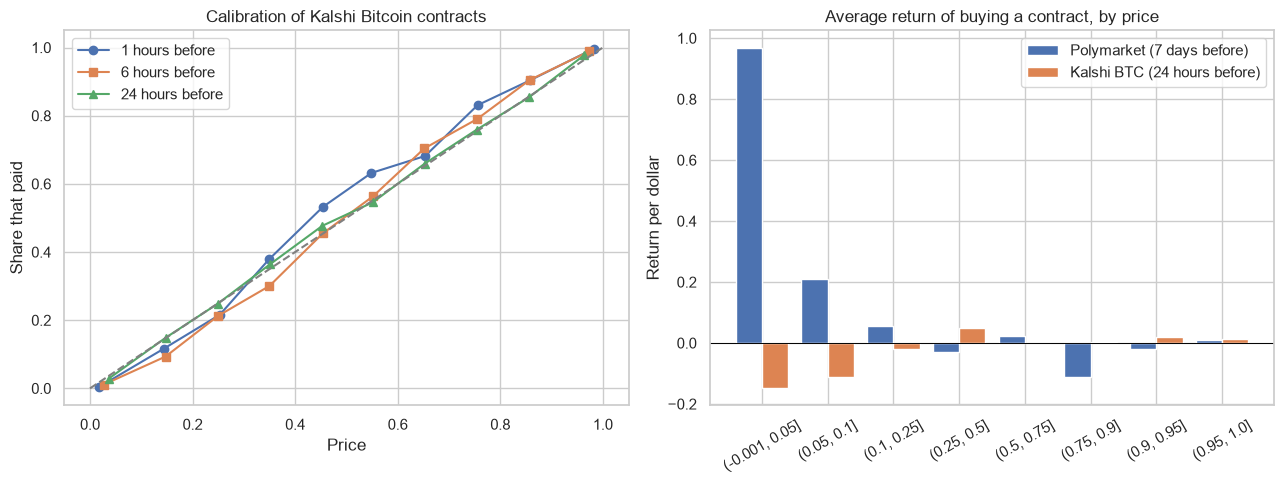

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for h, mk_ in [(1, "o"), (6, "s"), (24, "^")]:
    c = calibracion(kal[kal["hours_before"] == h], "mid", "paid")
    axes[0].plot(c["avg_price"], c["freq_paid"], marker=mk_, label=f"{h} hours before")
axes[0].plot([0, 1], [0, 1], ls="--", color="grey")
axes[0].set_title("Calibration of Kalshi Bitcoin contracts")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Share that paid")
axes[0].legend()
x = np.arange(len(flb_pm))
axes[1].bar(x - 0.2, flb_pm["return_per_dollar"], 0.4, label="Polymarket (7 days before)")
axes[1].bar(x + 0.2, flb_k["return_per_dollar"].reindex(flb_pm.index).values, 0.4, label="Kalshi BTC (24 hours before)")
axes[1].set_xticks(x, [str(i) for i in flb_pm.index], rotation=30)
axes[1].axhline(0, color="black", lw=0.7)
axes[1].set_title("Average return of buying a contract, by price")
axes[1].set_ylabel("Return per dollar")
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/favourite_longshot.png", bbox_inches="tight")
plt.show()

## Conclusions

- **Polymarket prices are good probabilities.** In 3.920 liquid markets of 2024 the calibration line is close to the diagonal: the regression of the outcome on the price has a slope of 0.98 (the test of slope = 1 has p = 0.39). With the same 409 markets at the three horizons, the Brier score improves from 0.110 thirty days before to 0.071 one week before and 0.052 one day before, against 0.180 for a constant forecast.
- **Kalshi Bitcoin contracts are even sharper,** because the event is a price that is observed all the time: Brier 0.019 one hour before the close, 0.052 six hours before and 0.094 one day before (0.250 for a constant forecast).
- **The favourite-longshot bias is there in the point estimates, but it is not significant.** Buying Kalshi contracts below 5 cents (at the mid, one day before) lost 15% on average, and between 5 and 10 cents 11%, while the expensive contracts were fair. But the contracts of one day move together: resampling days, the 95% interval of the return below 10 cents goes from -61% to +51%, and the slope of the calibration regression is 1.02 (p = 0.09 for slope = 1). In Polymarket the cheapest contracts even paid more than their price on average, but that depends on a few contracts that paid 20 to 50 times: the median return is -100% and the interval goes from -34% to +259%.
- **For the structured notes of my Graduating Project:** both markets give prices that can be used as probabilities, and the cost of using them is mostly the bid-ask, not a systematic bias. The tails are where the evidence is weakest: with 2 years of daily Bitcoin contracts, a premium of 10% to 15% on the price of far out of the money contracts cannot be ruled out nor confirmed. The next notebooks compare the Kalshi prices with the ones implied by the options market.